# 2024TSA Breed-Specific GWAS


- Which measured markers are associated with behavioral elimination within each breed?
- GEMMA and GMMAT analyze LR and GSP separately, with sex and relatedness adjustment
- Scheme A includes 46 LR and 105 GSP
- Scheme B includes 48 LR and 116 GSP.
- Association tests measure evidence linking genotype to outcome
- Manhattan and quantile–quantile plots summarize the results.
- These methods do not establish causal variants or genes, and significance alone does not establish reliable effects in small case groups.

### (Initialization) Import Directory-Free Helpers

In [1]:
# Locate the repository and verify all four aligned genotype datasets before reviewing measured-marker scans.

from pathlib import Path
import importlib
import sys
study_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/notebook_support.py").exists())
sys.path.insert(0, str(study_root / "scripts"))
read_json = importlib.import_module("notebook_support").read_json
file_digest = importlib.import_module("notebook_support").file_digest
study_path = importlib.import_module("notebook_support").study_path
verify_datasets = importlib.import_module("notebook_support").verify_datasets
require_saved = importlib.import_module("notebook_review").require_saved
run_script = importlib.import_module("notebook_support").run_script

### (Parse) Load Dogs and Markers

In [2]:
alignment = read_json(study_root / "data/02-aligned/manifest.private.json")
assert alignment["status"] == "complete"
verify_datasets(study_root, alignment)
print("Four aligned genotype datasets verified.")

Four aligned genotype datasets verified.


### Dogs and Markers Summary
- Markers pass QC and CanFam4 alignment, then a 2.5% frequency cutoff within each analysis.
- Missing numerical entries use the observed cohort mean for both methods.
- Original calls stay unchanged.

| Breed | Scheme | Controls | Cases | Dogs | Aligned Candidate Markers |
| :---: | :---: | :---: | :---: | :---: | :---: |
| LR | A | 39 | 7 | 46 | 168,341 |
| LR | B | 41 | 7 | 48 | 168,341 |
| GSP | A | 96 | 9 | 105 | 165,064 |
| GSP | B | 107 | 9 | 116 | 165,064 |


### (Model Design) Account for Related Dogs
- Both models include sex and the same chromosome-excluded matrix from pruned background markers.
- Their results are alternative analyses, not independent replication.

In [3]:
# Load GSP background markers and define the chromosome-excluded relationship calculation.
# This exposes how genetic similarity is calculated without using the chromosome under test.

import numpy as np
from replication_models import standardized_background

def chromosome_excluded_relationship(standardized_genotypes, chromosomes, tested_chromosome, indices):
    """Average genetic similarity outside the chromosome being tested."""
    background = standardized_genotypes[chromosomes != tested_chromosome][:, indices]
    return background.T @ background / len(background)

breed = "GSP"
background_prefix = study_root / f"data/03-structure/20261002-pca-umap-tsne/{breed}/02_pruned_genotypes"
aligned_bim = study_root / f"data/02-aligned/not-behelim-vs-behelim/{breed}/2024TSA_{breed}.bim"
background_ids, chromosomes, standardized_genotypes = standardized_background(background_prefix, aligned_bim)
print(breed, "aligned background markers:", len(chromosomes))

GSP aligned background markers: 15794


### (Association Testing) Breed-Specific GWAS (Scheme A)
- The code checks 152 chromosome analyses and their recorded inputs.
- *breed_gwas.py*

In [4]:
# Run the breed-specific scans only if their manifest is absent, then verify completion and source hashes.
# The checks cover both breeds, both control definitions and all autosomes.

gwas_folder = study_root / "data/07-gwas/measured-20261004"
manifest_path = gwas_folder / "manifest.private.json"
# if not manifest_path.exists():
#     run_script(study_root, "breed_gwas.py", "--output", gwas_folder, linux=True)
scans = read_json(manifest_path)
assert scans["status"] == "paired_measured_scans_complete"
assert scans["chromosomes"] == list(range(1, 39))
assert len(scans["jobs"]) == 152
saved_plan = read_json(gwas_folder / "plan.private.json")
assert saved_plan["config"] == read_json(study_root / "config/gwas.json")
for name, digest in saved_plan["scripts"].items():
    assert file_digest(study_root / "scripts" / name) == digest
for source, digest in saved_plan["sources"].items():
    assert file_digest(study_path(study_root, source)) == digest
print("Completed: 38 chromosomes × two breeds × two control comparisons.")

Completed: 38 chromosomes × two breeds × two control comparisons.


### (Consistency Check) Check One Relationship Matrix
- One GSP matrix is independently rebuilt and compared with its model input.

In [5]:
# Rebuild one GSP relationship matrix in the recorded dog order and compare it with the model input.
# This independently checks the relationship calculation used in the scan.

import csv
example = next(job for job in scans["jobs"] if job["breed"] == "GSP")
folder = study_path(study_root, example["folder"])
with (folder / "dogs.private.tsv").open(encoding="utf-8", newline="") as handle:
    dogs = list(csv.DictReader(handle, delimiter="\t"))
positions = {dog_id: i for i, dog_id in enumerate(background_ids)}
indices = [positions[dog["id"]] for dog in dogs]
reconstructed = chromosome_excluded_relationship(
    standardized_genotypes, chromosomes, example["chromosome"], indices)
assert np.allclose(reconstructed, np.loadtxt(folder / "kinship.txt"), atol=1e-12)
print("GSP relationship calculation matches the supplied matrix.")

GSP relationship calculation matches the supplied matrix.


### (Visualization) Genome-Wide Results
- Bonferroni cutoffs use original aligned candidate counts within each breed-specific analysis.
- No additional correction spans breeds, methods or test types.
- Wald, likelihood-ratio and score tests remain separate.
- Crossing a line identifies a candidate, not a validated discovery.
- *summarize_gwas.py*

| Breed | Calculation | Cutoff |
| :---: | :---: | :---: |
| LR | 0.05 / 168,341 | 2.97 × 10⁻⁷ |
| GSP | 0.05 / 165,064 | 3.03 × 10⁻⁷ |


In [6]:
# Summarize completed GWAS outputs and verify the reporting-policy hash.
# Display cohort and marker counts so each reported scan has an explicit analysis family.

figure_folder = study_root / "results/private/version2/07_breed_specific_gwas"
# run_script(study_root, "summarize_gwas.py", "--run-dir", gwas_folder,
#            "--results-dir", figure_folder)
summary = read_json(figure_folder / "summary.private.json")
reporting = read_json(study_root / "config/gwas_reporting.json")
assert summary["reporting_policy_sha256"] == file_digest(study_root / "config/gwas_reporting.json")
assert reporting["reporting_method"] == "GEMMA"
assert reporting["comparison_method"] == "GMMAT"
from IPython.display import Markdown, Image, display
lines = ["| Breed | Comparison | Markers | Dogs | Cases |",
         '| :---: | :---: | :---: | :---: | :---: |']
for group in summary["groups"]:
    label = "A: primary" if group["scenario"] == scans["config"]["primary_cohort"] else "B: sensitivity"
    lines.append(f"| {group['breed']} | {label} | {group['eligible_markers']:,} | {group['dogs']} | {group['cases']} |")
display(Markdown("\n".join(lines)))

| Breed | Comparison | Markers | Dogs | Cases |
| :---: | :---: | :---: | :---: | :---: |
| LR | A: primary | 167,571 | 46 | 7 |
| LR | B: sensitivity | 168,341 | 48 | 7 |
| GSP | A: primary | 162,990 | 105 | 9 |
| GSP | B: sensitivity | 165,064 | 116 | 9 |

### LR: primary measured scan

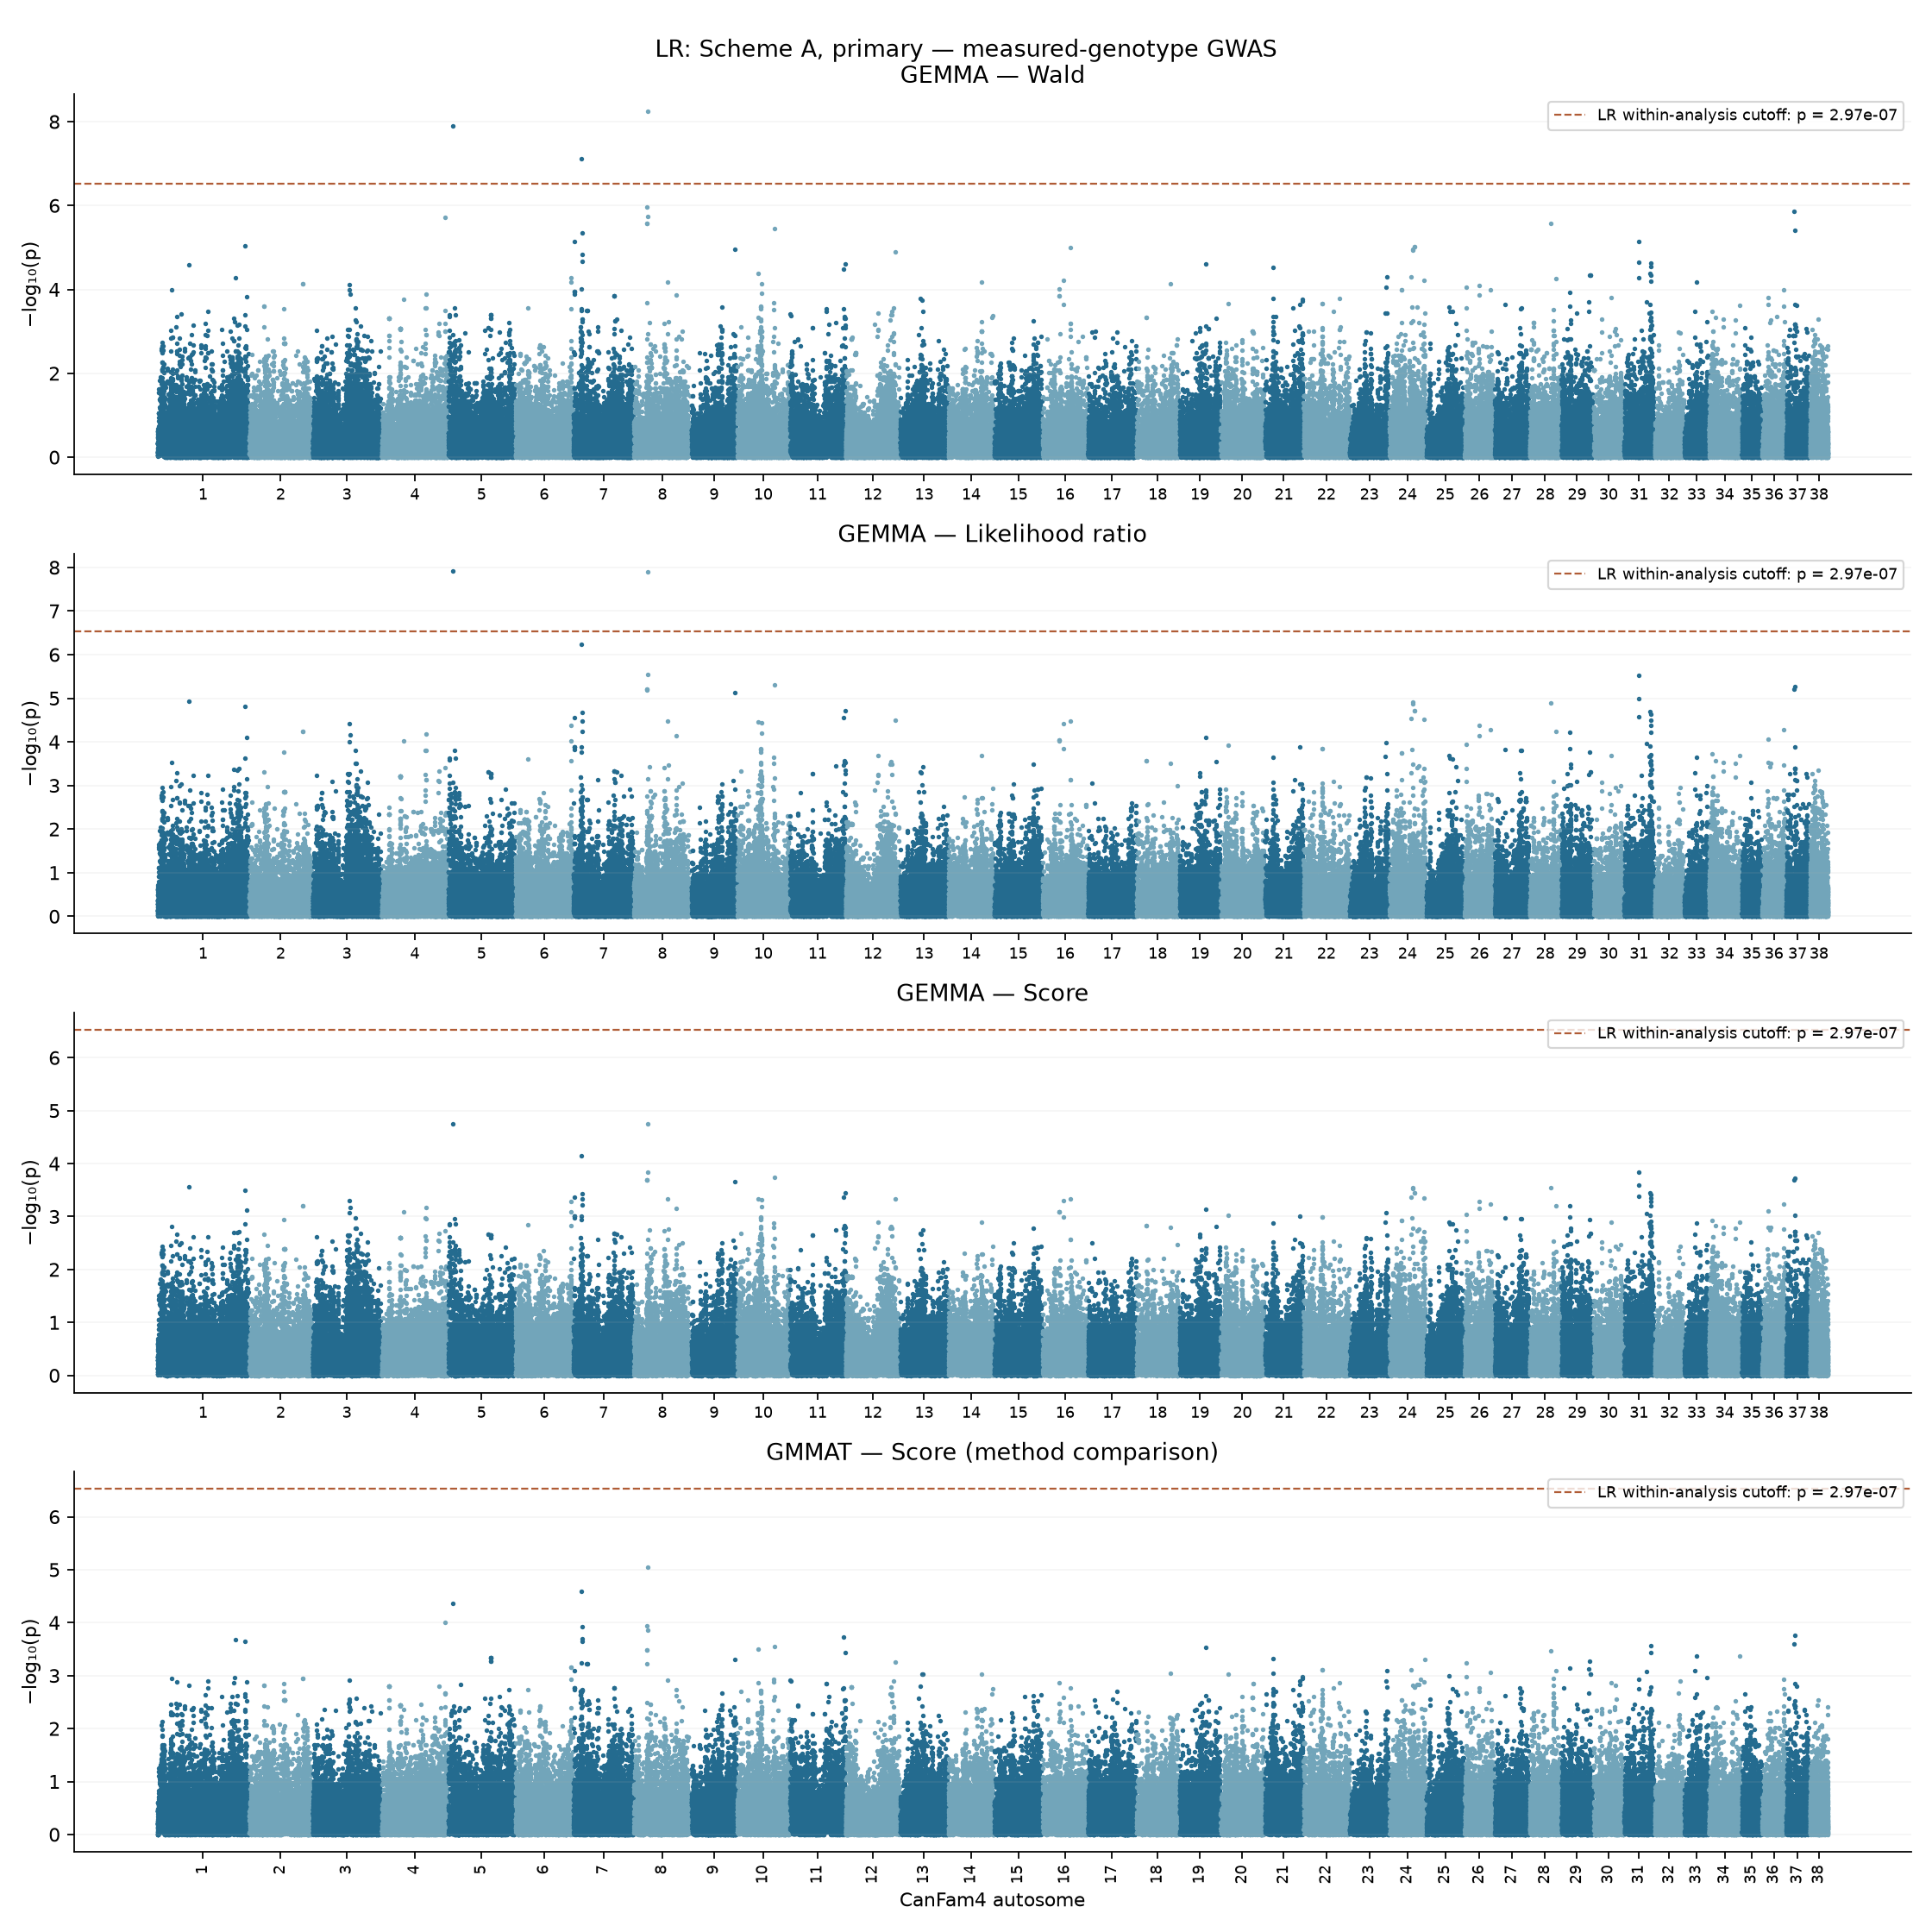

### GSP: primary measured scan

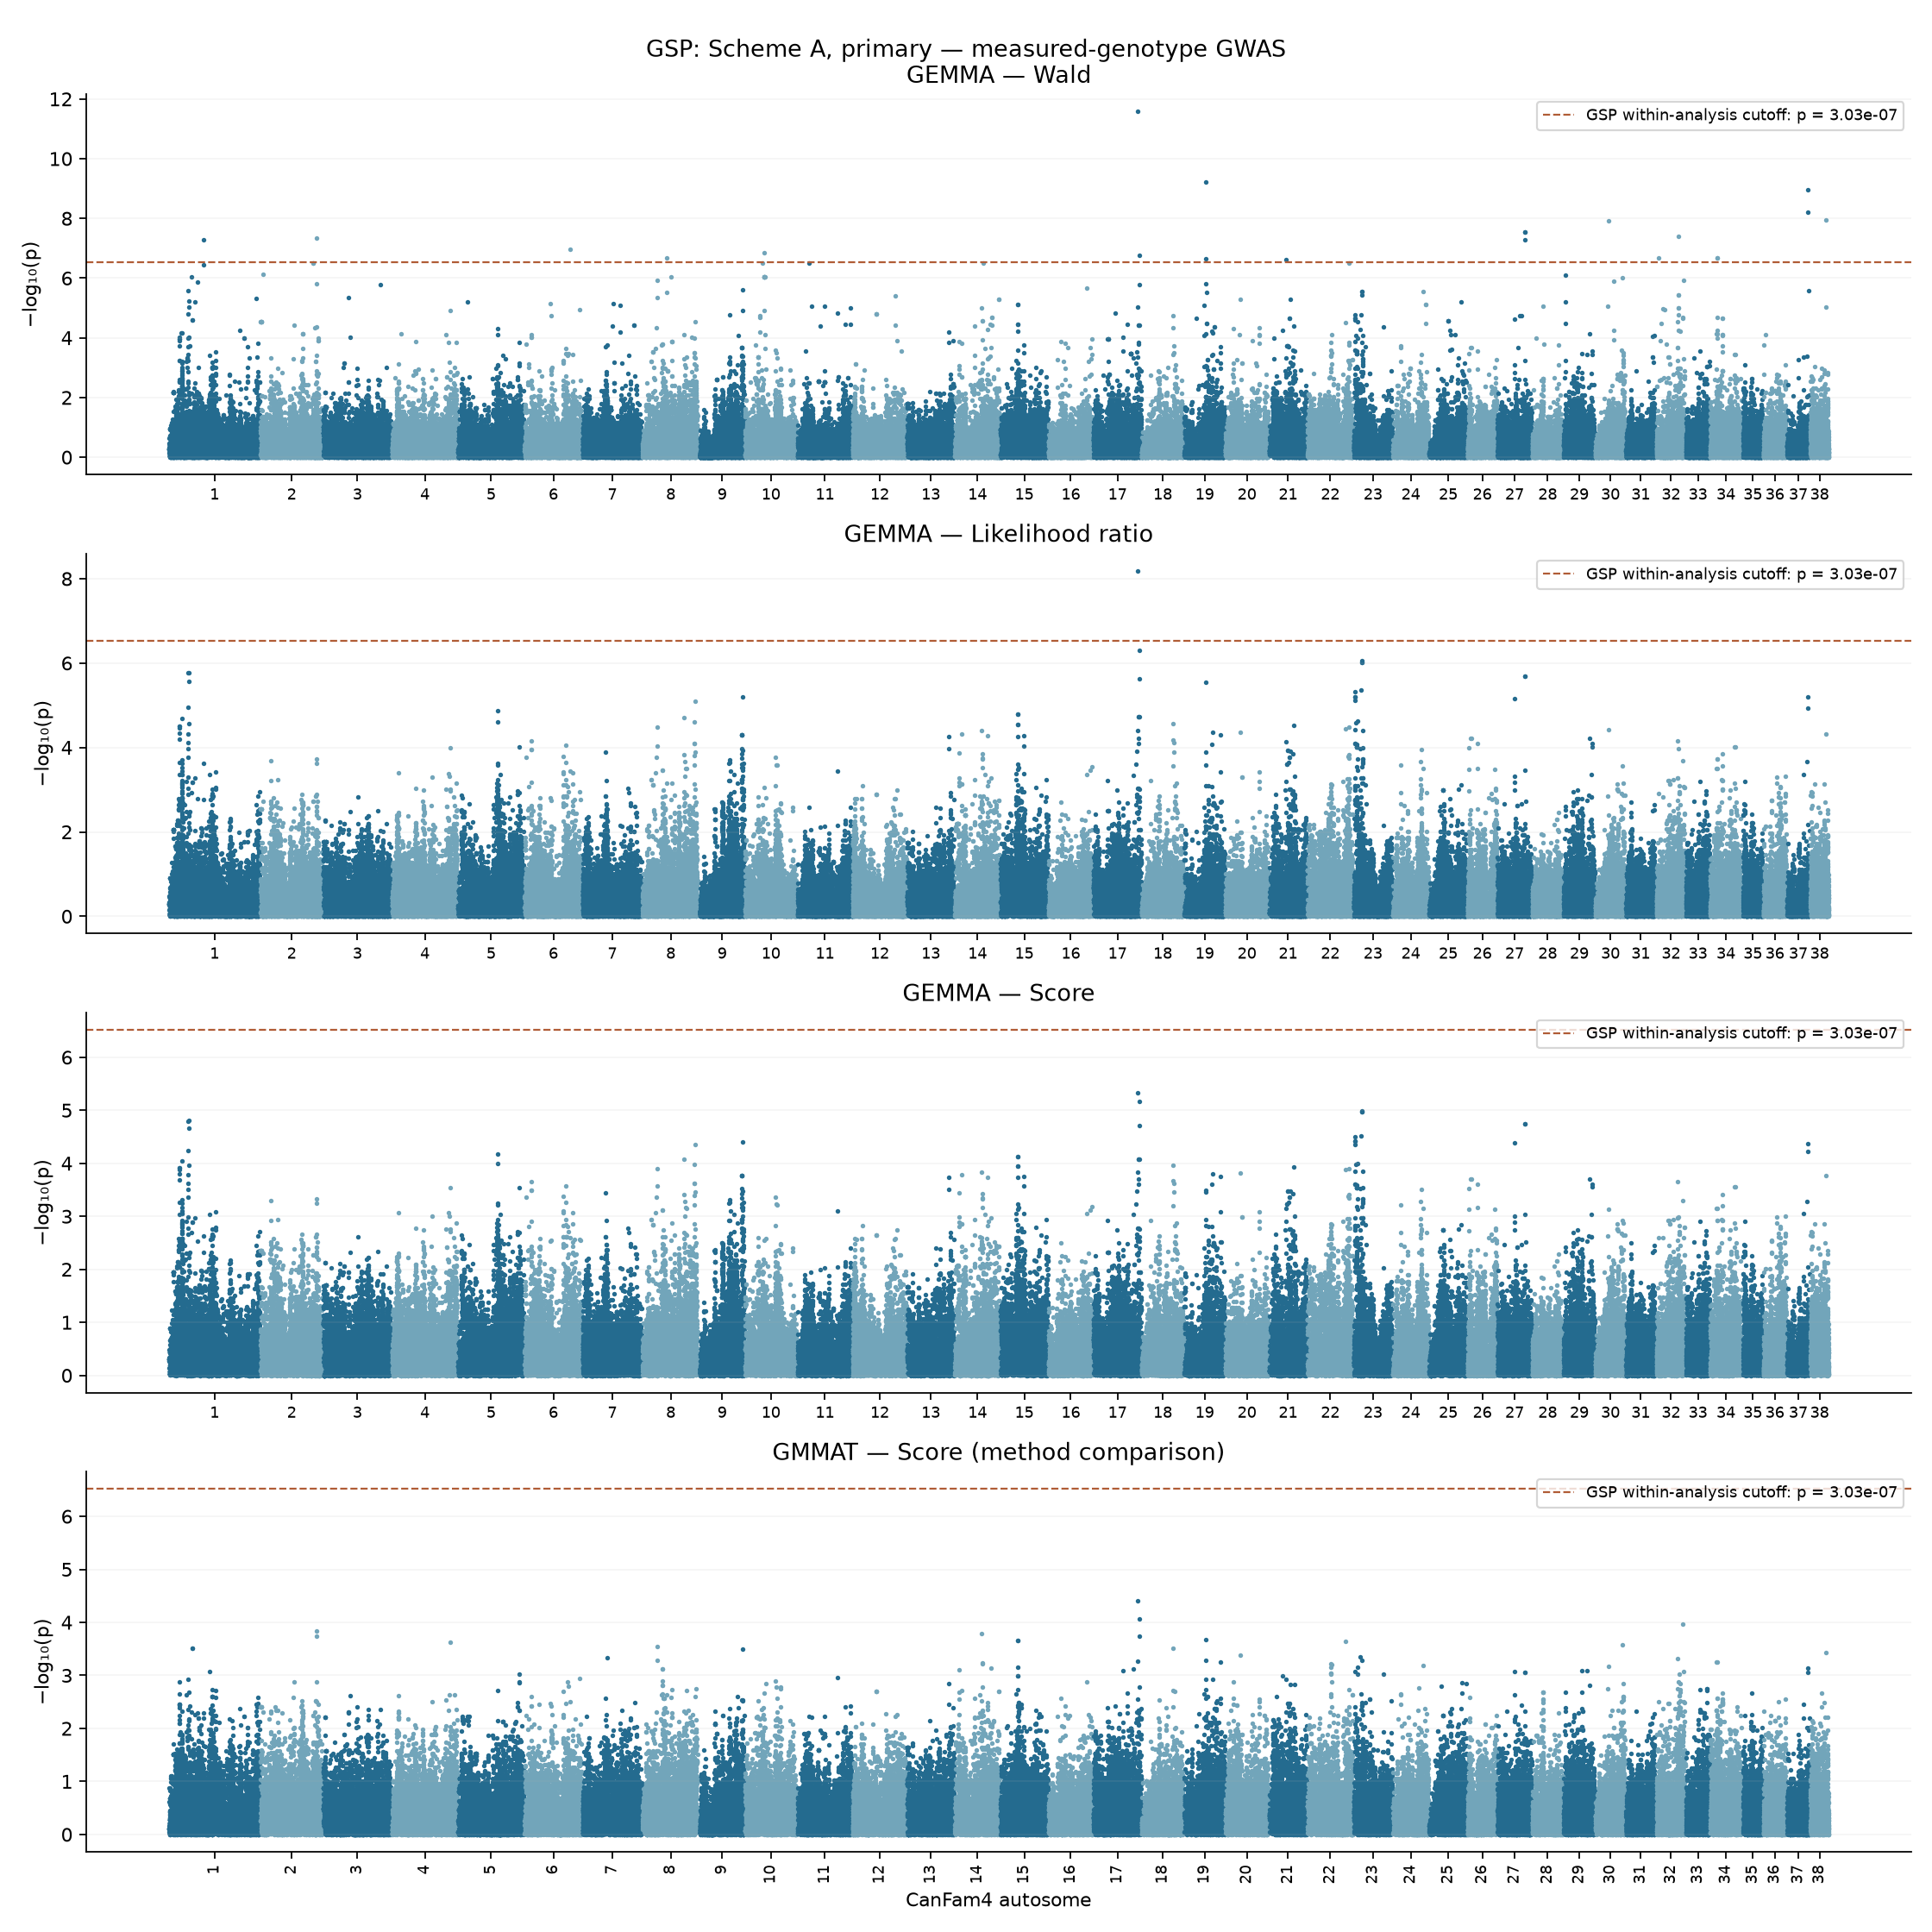

In [7]:
# Display the primary measured-marker Manhattan plots separately for LR and GSP.

for breed in ["LR", "GSP"]:
    display(Markdown(f"### {breed}: primary measured scan"))
    display(Image(filename=str(figure_folder / f"{breed}_success-vs-behelim_manhattan.png")))

### (Visualization) Quantile–Quantile Plots
- QQ plots compare probabilities with an ideal null distribution.
- Related markers, sparse genotypes and model behavior complicate interpretation.
- A median ratio near one does not validate extreme probabilities.

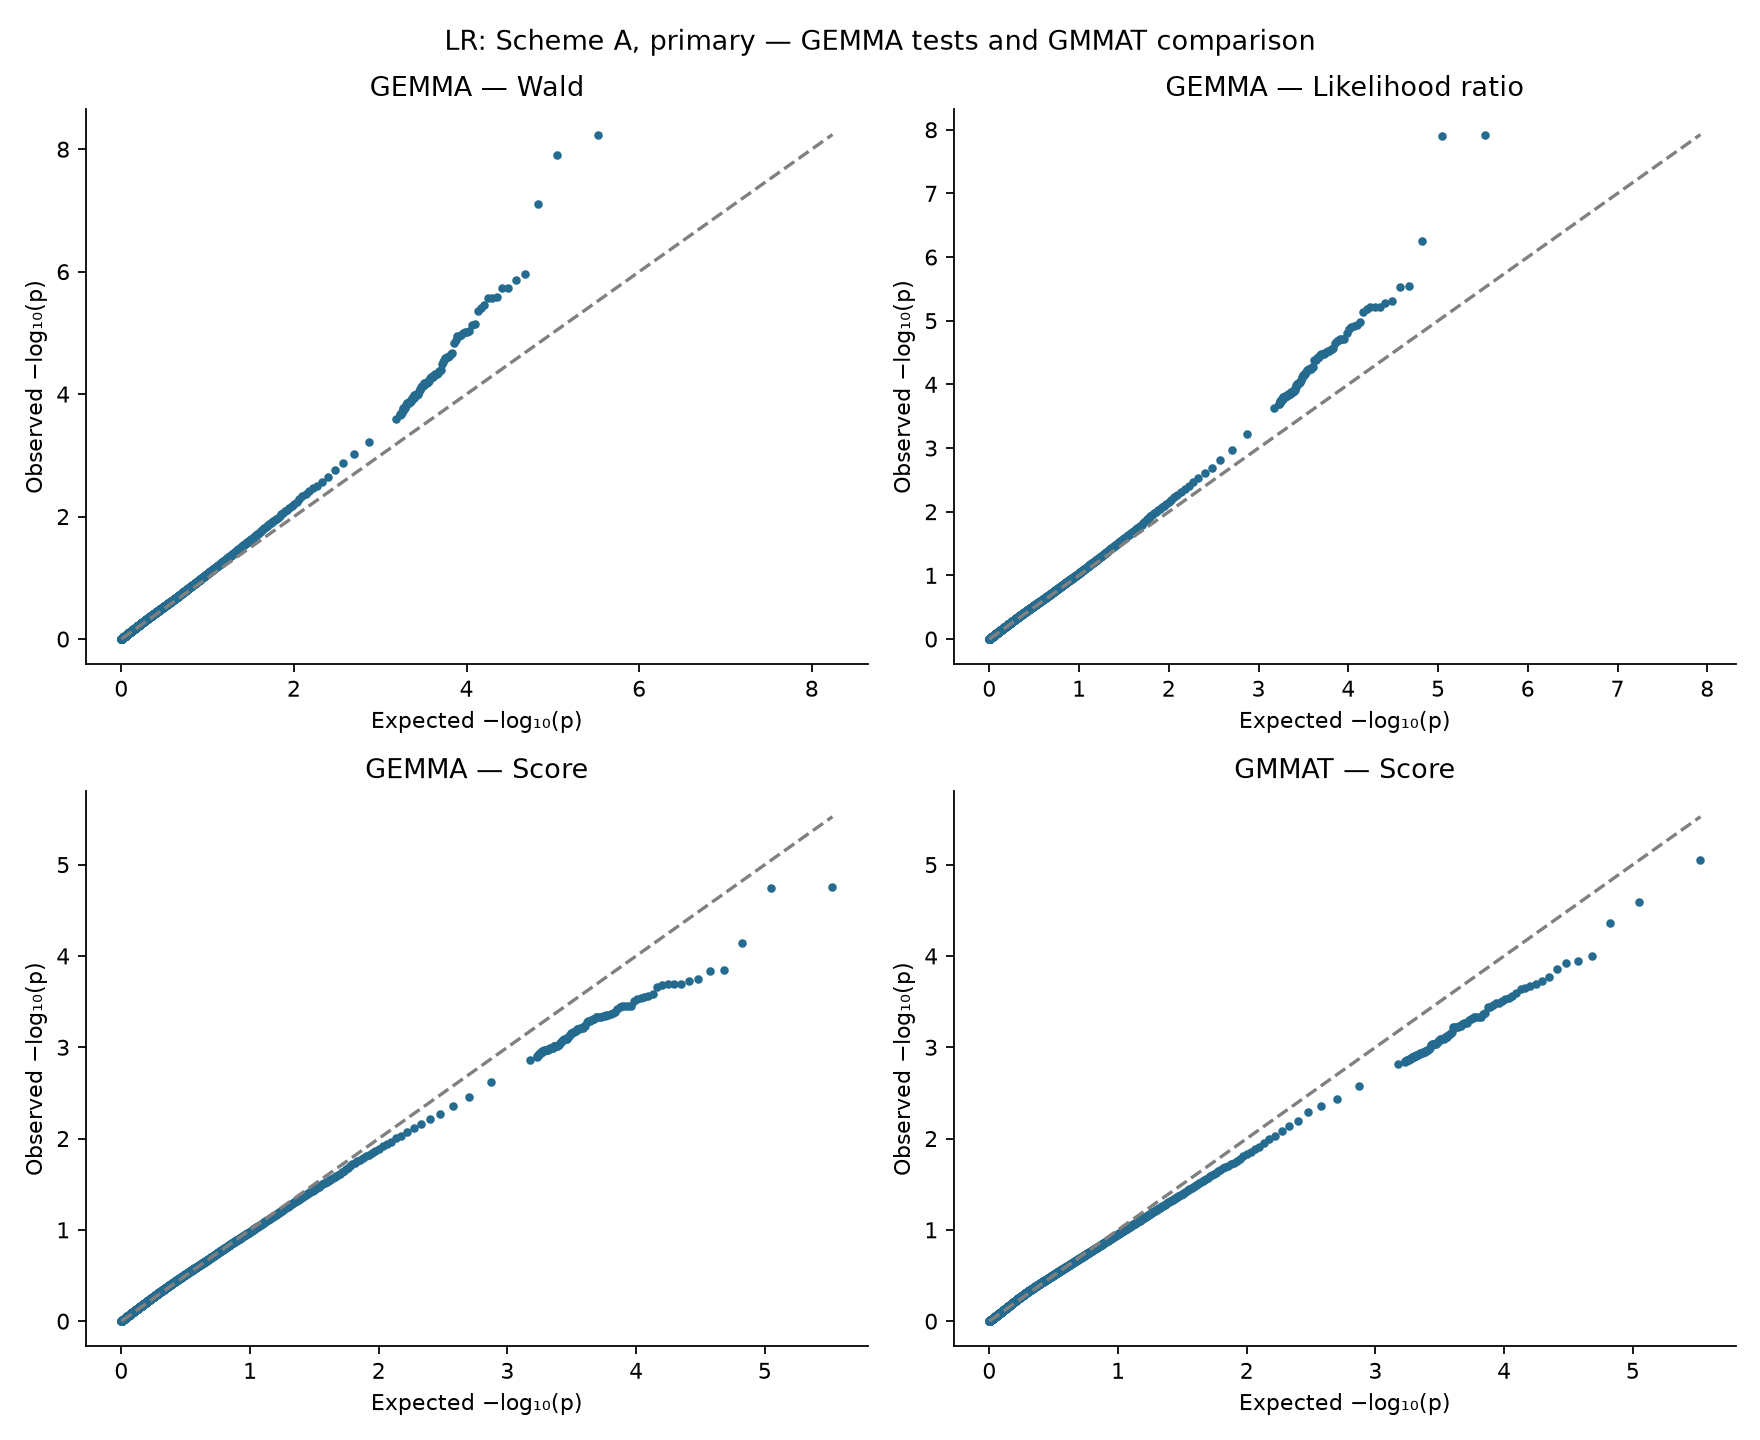

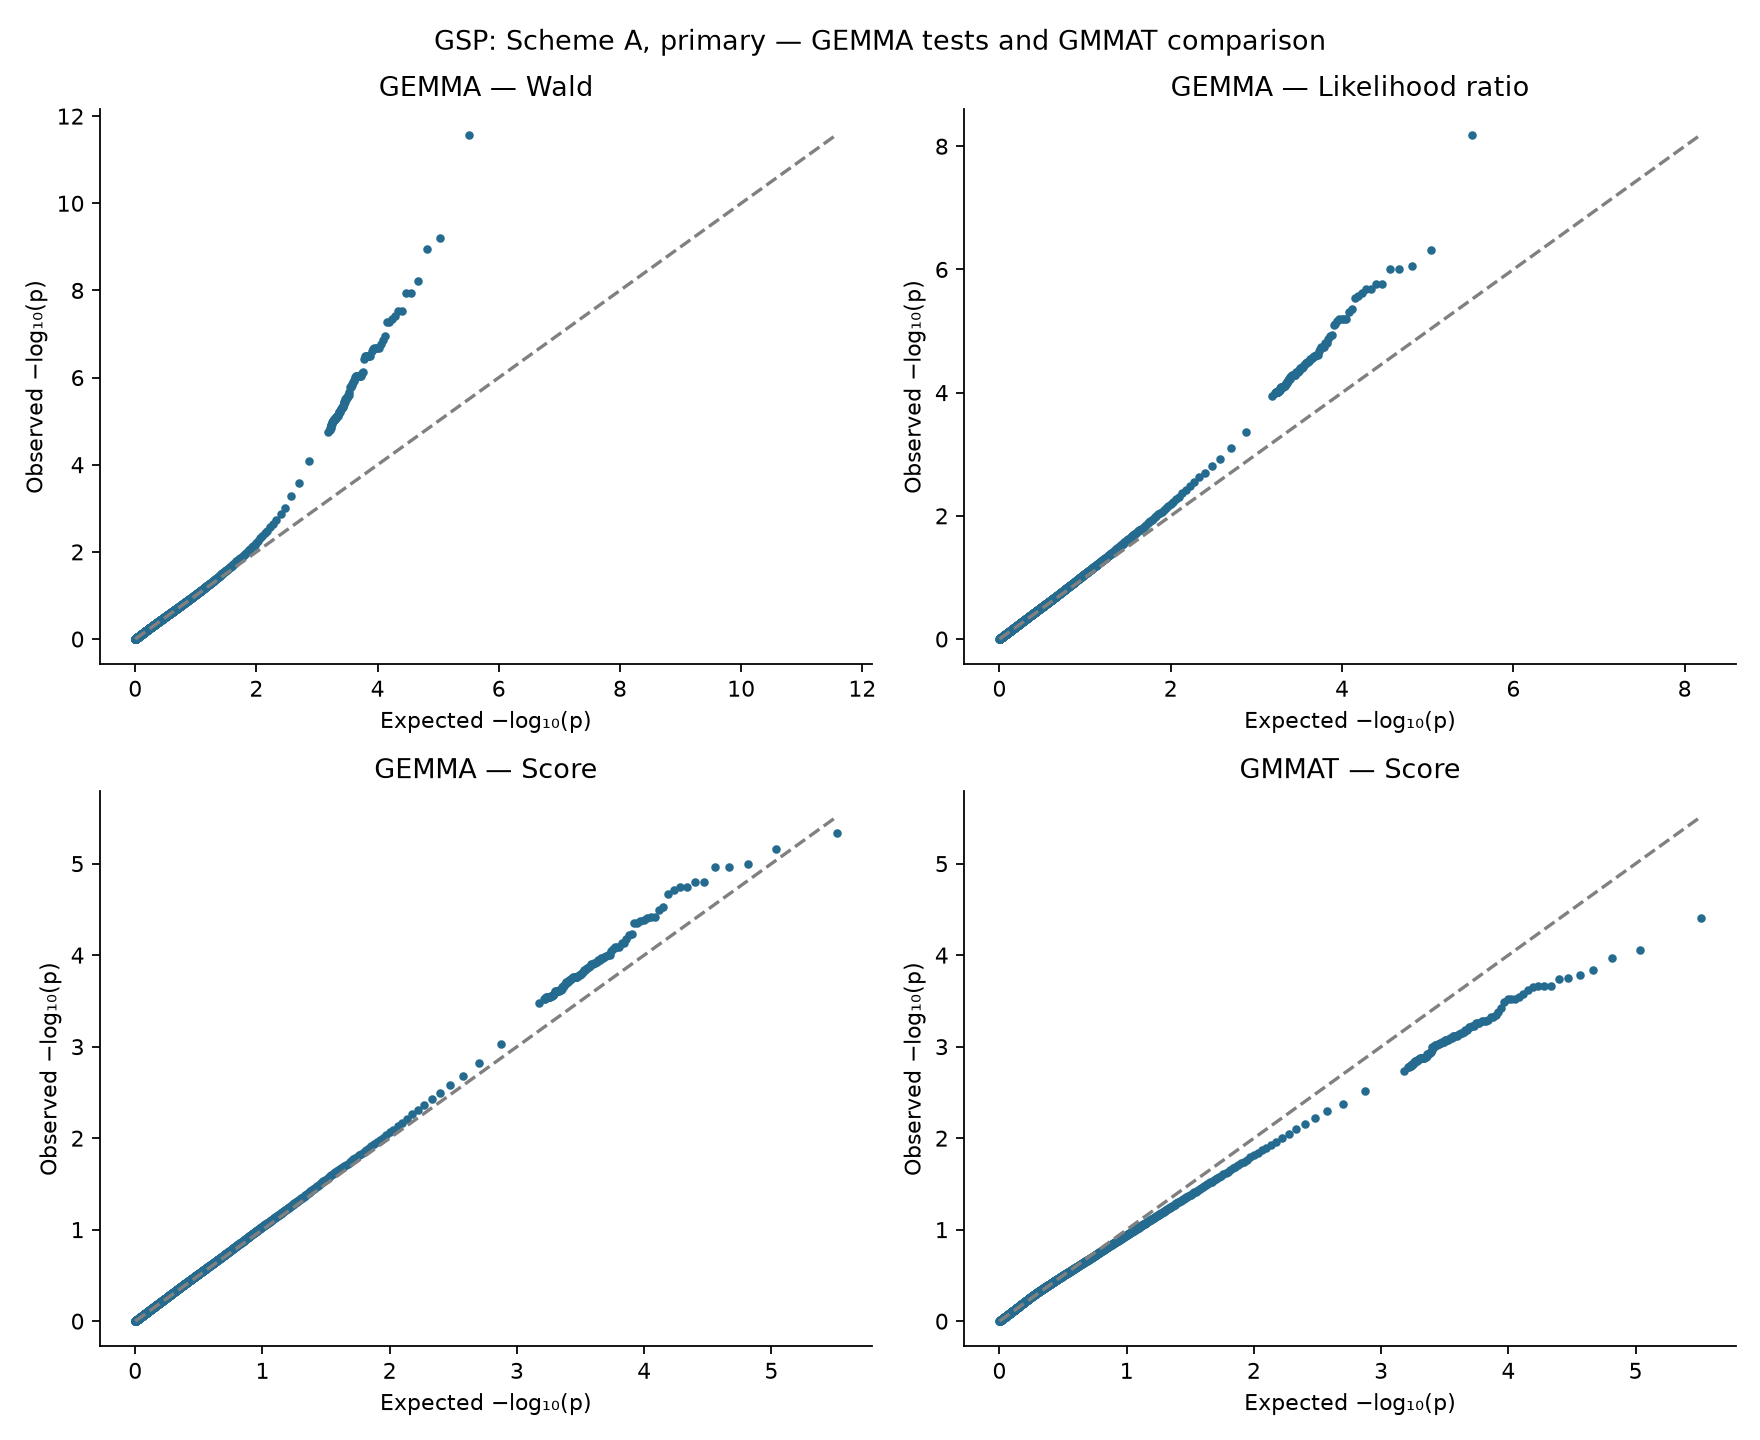

| Breed | Method | Test | Valid Tests | Smallest P | Within-Analysis Cutoff | Markers Below Cutoff | Median Chi-Square Ratio |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| LR | GEMMA | Wald | 167,559 | 5.77e-09 | 2.97e-07 | 3 | 1.167 |
| LR | GEMMA | Likelihood ratio | 167,571 | 1.19e-08 | 2.97e-07 | 2 | 1.131 |
| LR | GEMMA | Score | 167,571 | 1.78e-05 | 2.97e-07 | 0 | 1.105 |
| LR | GMMAT | Score | 167,571 | 8.96e-06 | 2.97e-07 | 0 | 1.140 |
| GSP | GEMMA | Wald | 162,990 | 2.65e-12 | 3.03e-07 | 21 | 1.074 |
| GSP | GEMMA | Likelihood ratio | 162,990 | 6.46e-09 | 3.03e-07 | 1 | 1.084 |
| GSP | GEMMA | Score | 162,990 | 4.61e-06 | 3.03e-07 | 0 | 1.074 |
| GSP | GMMAT | Score | 162,990 | 3.96e-05 | 3.03e-07 | 0 | 1.083 |

In [8]:
# Display primary QQ plots and test-specific summary statistics.
# Separate rows retain differences among model tests instead of treating them as independent confirmation.

for breed in ["LR", "GSP"]:
    display(Image(filename=str(figure_folder / f"{breed}_success-vs-behelim_qq.png")))
lines = ['| Breed | Method | Test | Valid Tests | Smallest P | Within-Analysis Cutoff | Markers Below Cutoff | Median Chi-Square Ratio |',
         "| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |"]
for result in summary["tests"]:
    if result["scenario"] != scans["config"]["primary_cohort"]: continue
    lines.append(f"| {result['breed']} | {result['method']} | {result['test']} | {result['valid_tests']:,} | "
                 f"{result['minimum_p']:.3g} | {result['threshold']:.3g} | {result['below_analysis_threshold']} | "
                 f"{result['median_chi_square_ratio']:.3f} |")
display(Markdown("\n".join(lines)))

- All 152 GMMAT null models converge.
- Both methods return finite score probabilities.
- Median chi-square ratios are 1.140 / 1.105 in LR and 1.083 / 1.074 in GSP (GMMAT / GEMMA).
- GEMMA alternative variance estimates reach a boundary at every LR marker and almost every GSP marker.
- Some LR effects are unavailable.

### (Sensitivity Analysis) Broad Breed-Specific GWAS (Scheme B)
- Scheme B retains the same cases and adds accepted other eliminations as controls.
- It remains a sensitivity comparison even when probabilities are smaller.

### LR: sensitivity comparison

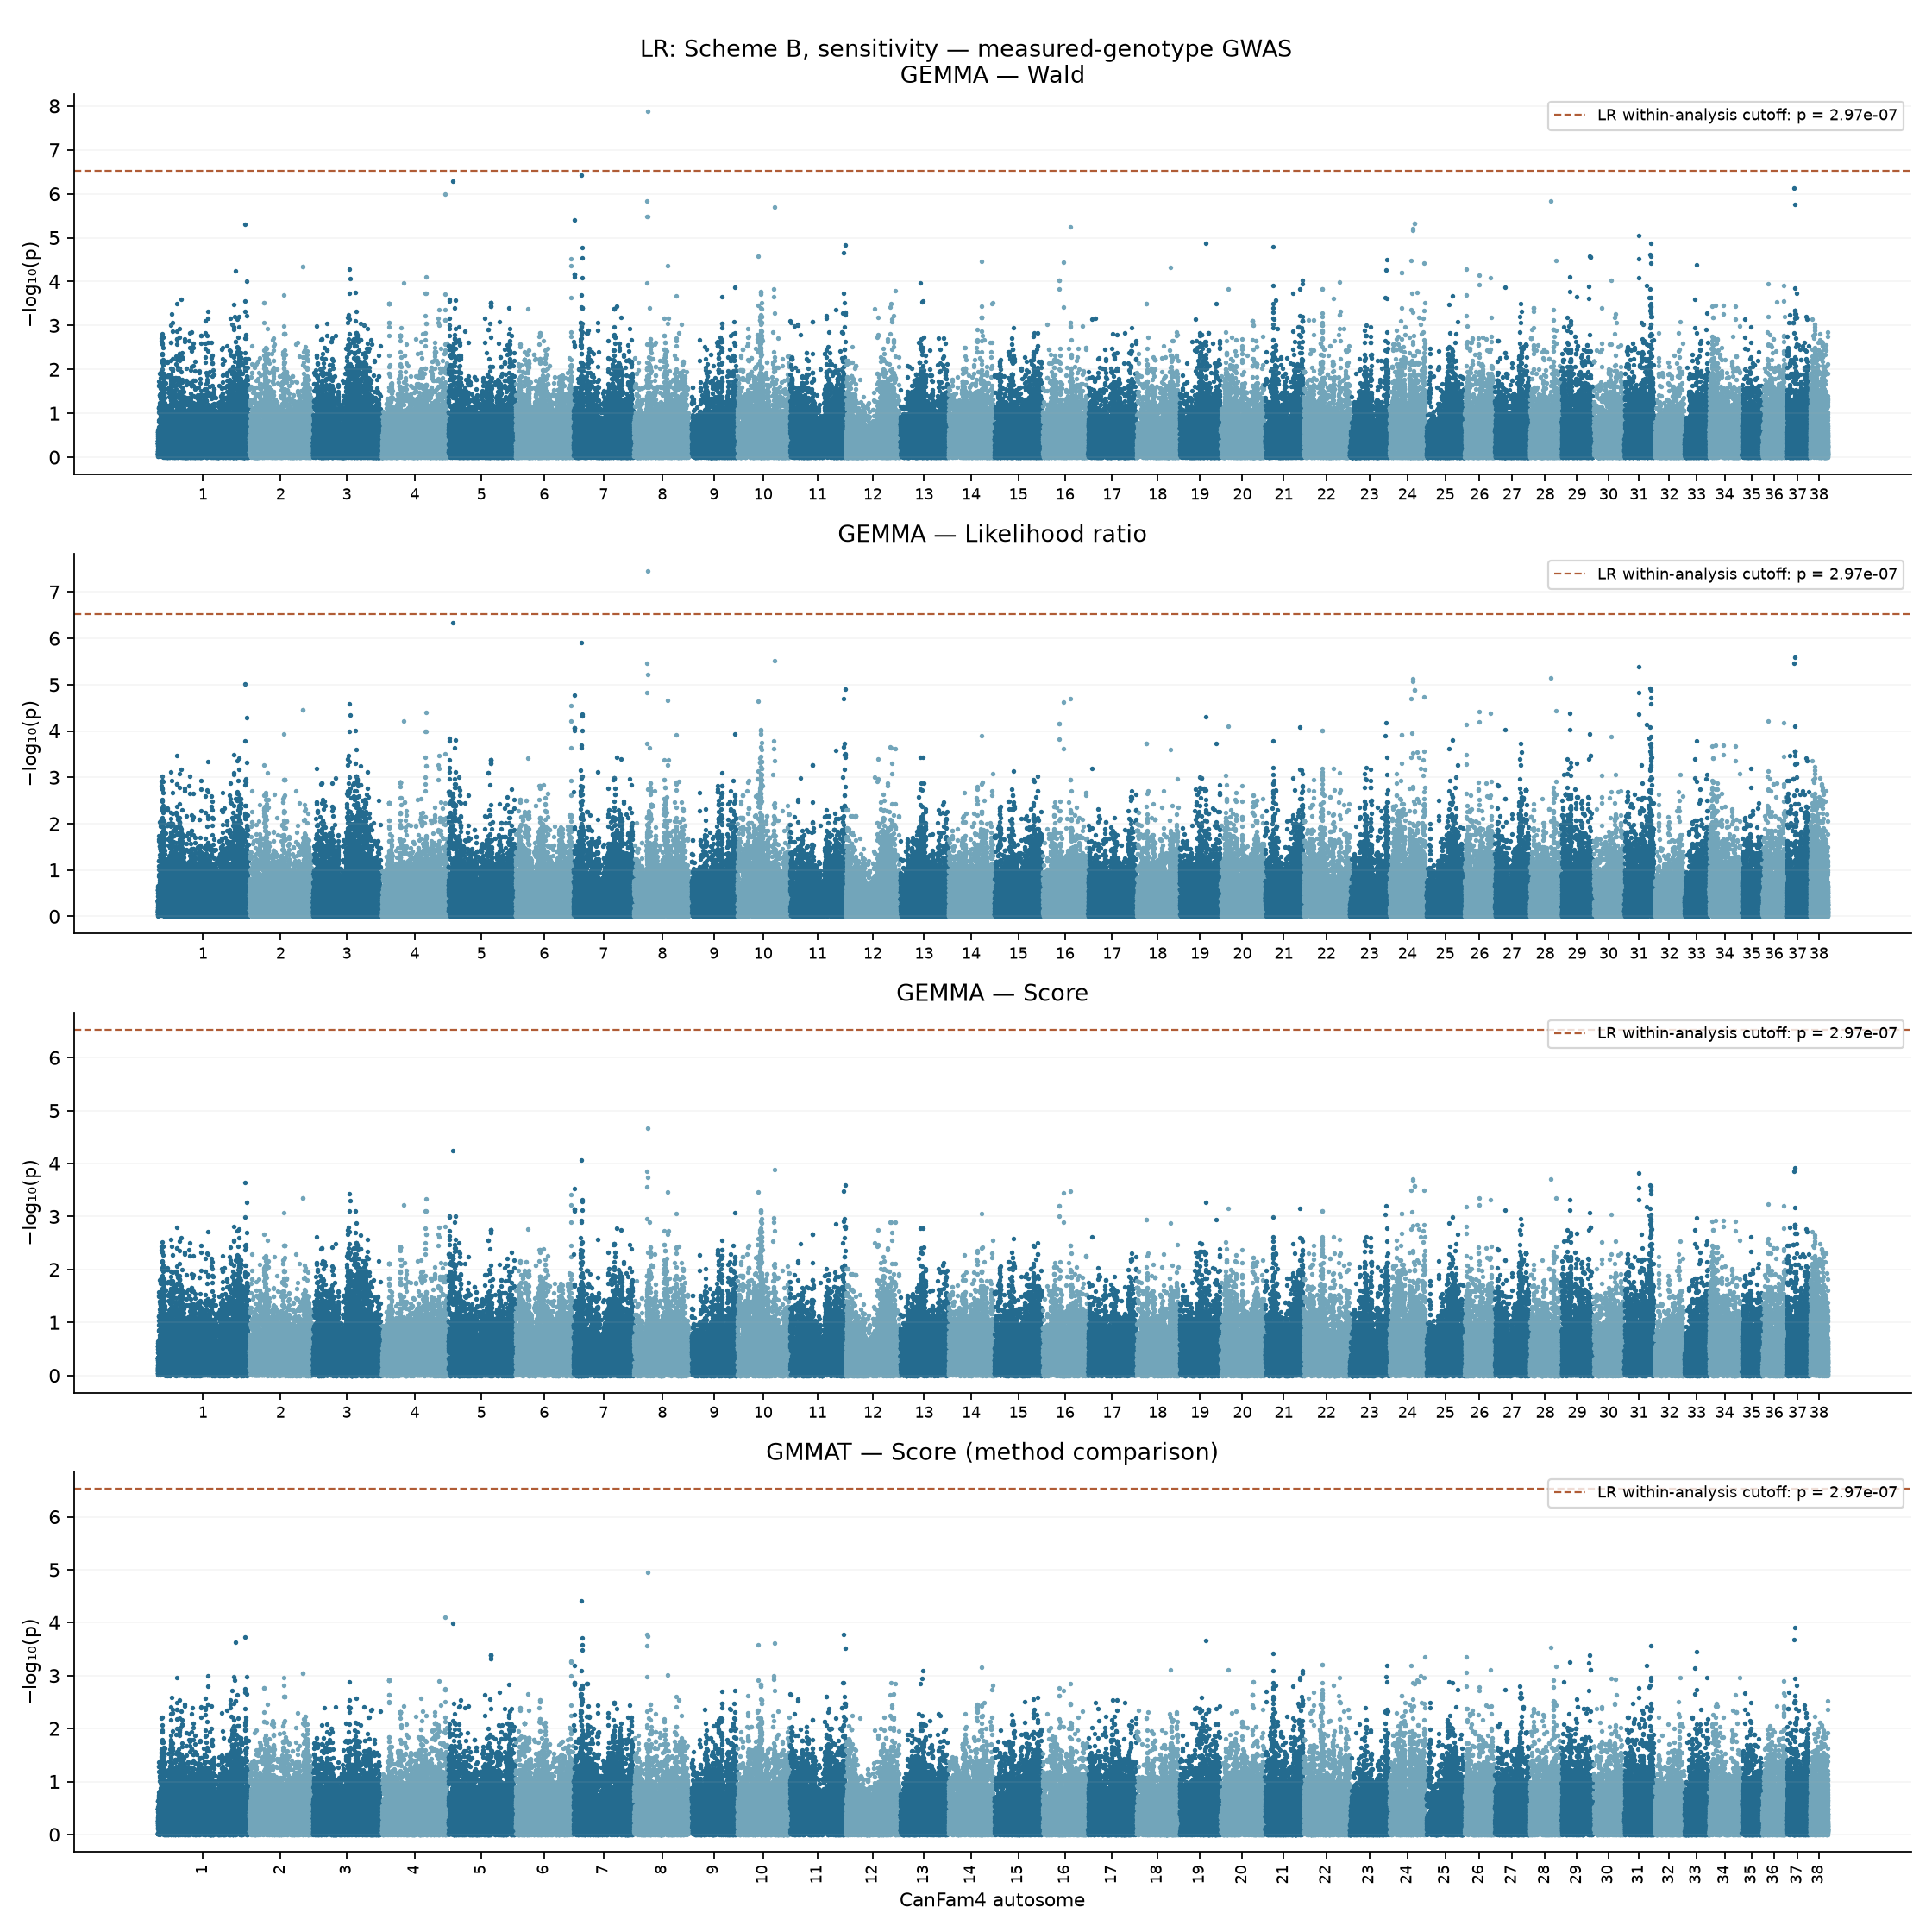

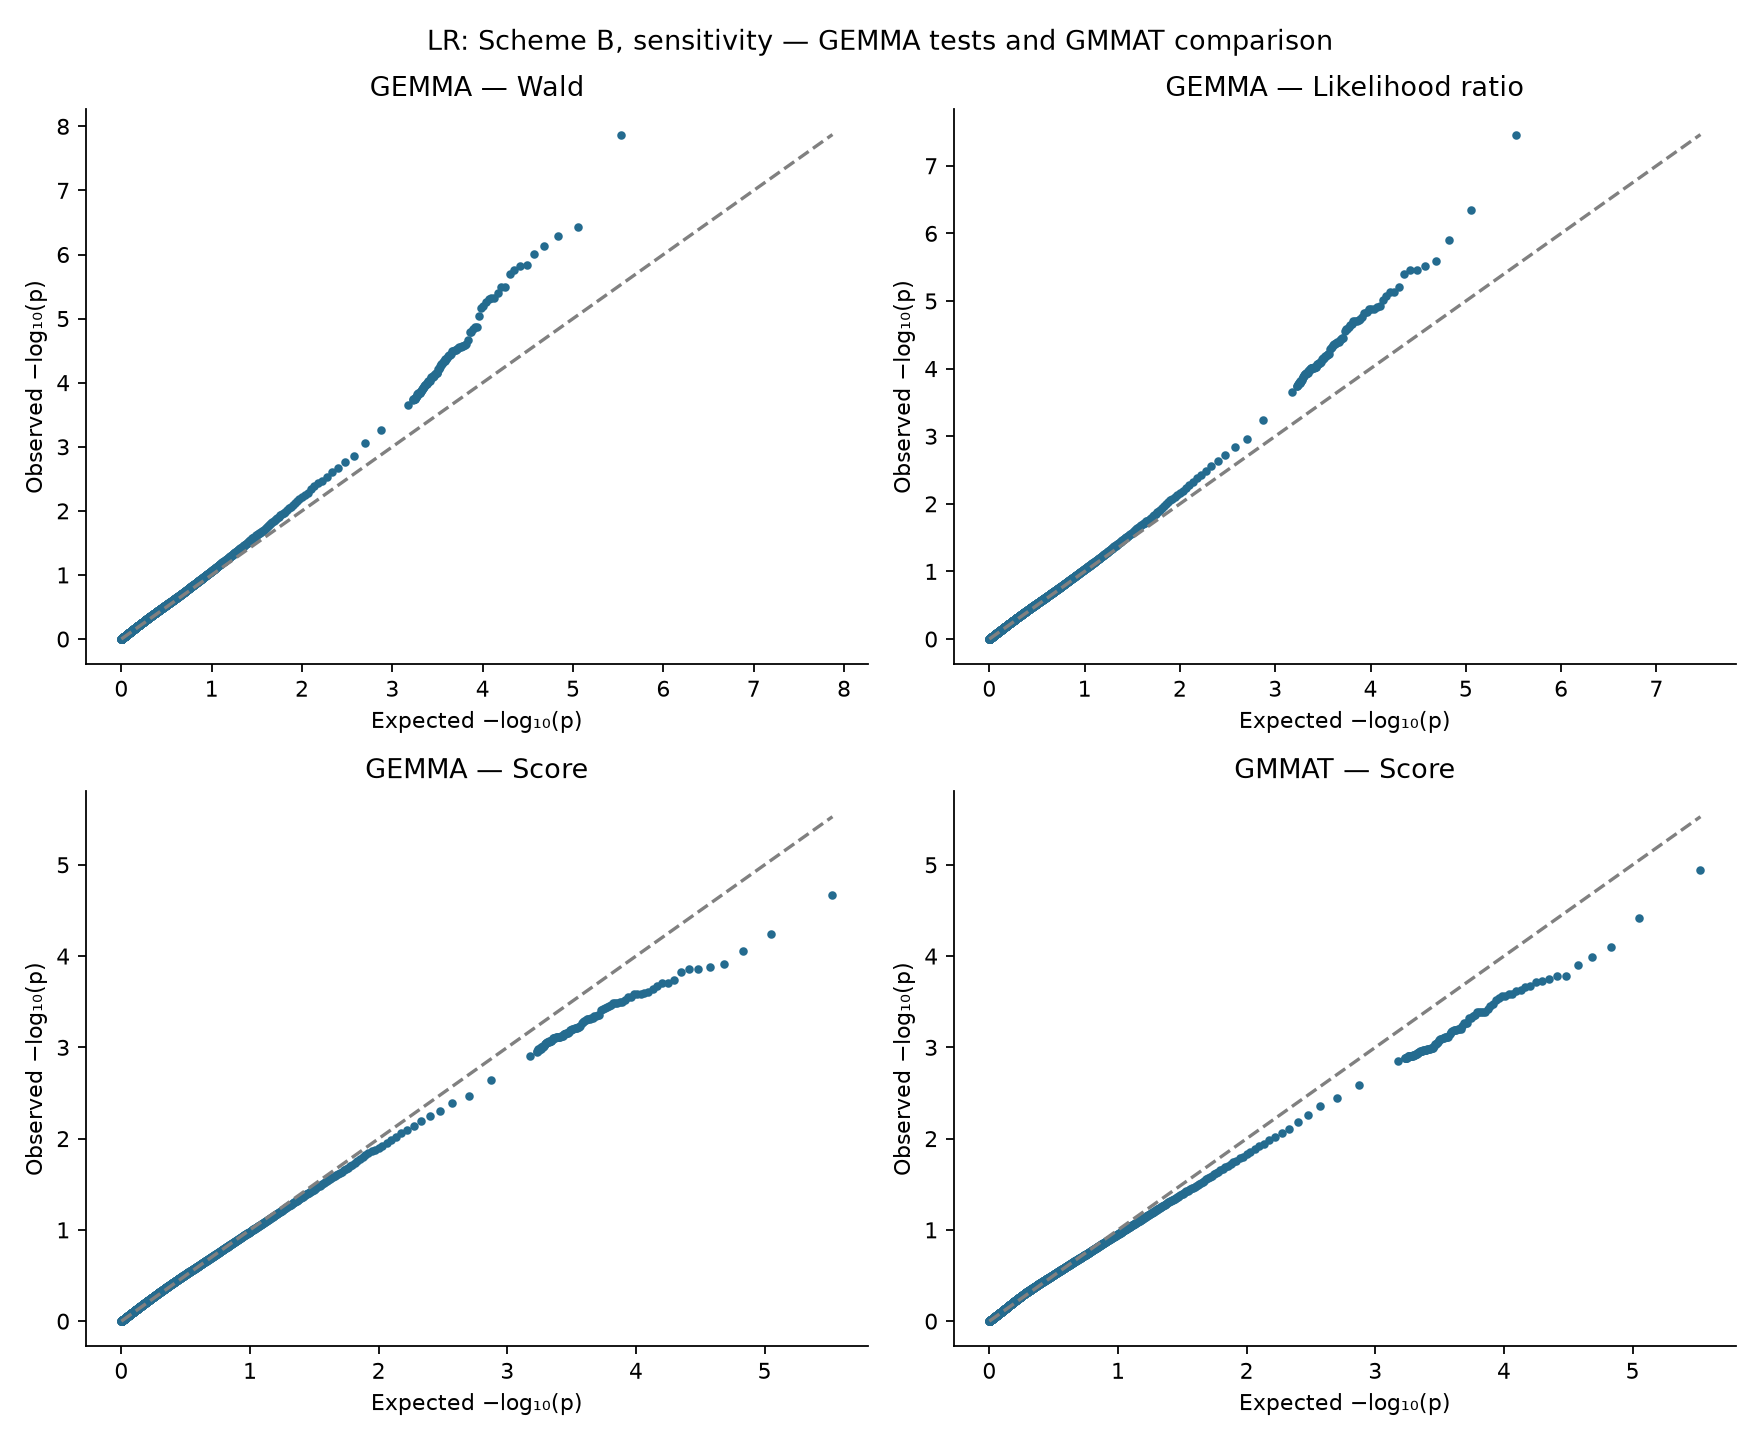

### GSP: sensitivity comparison

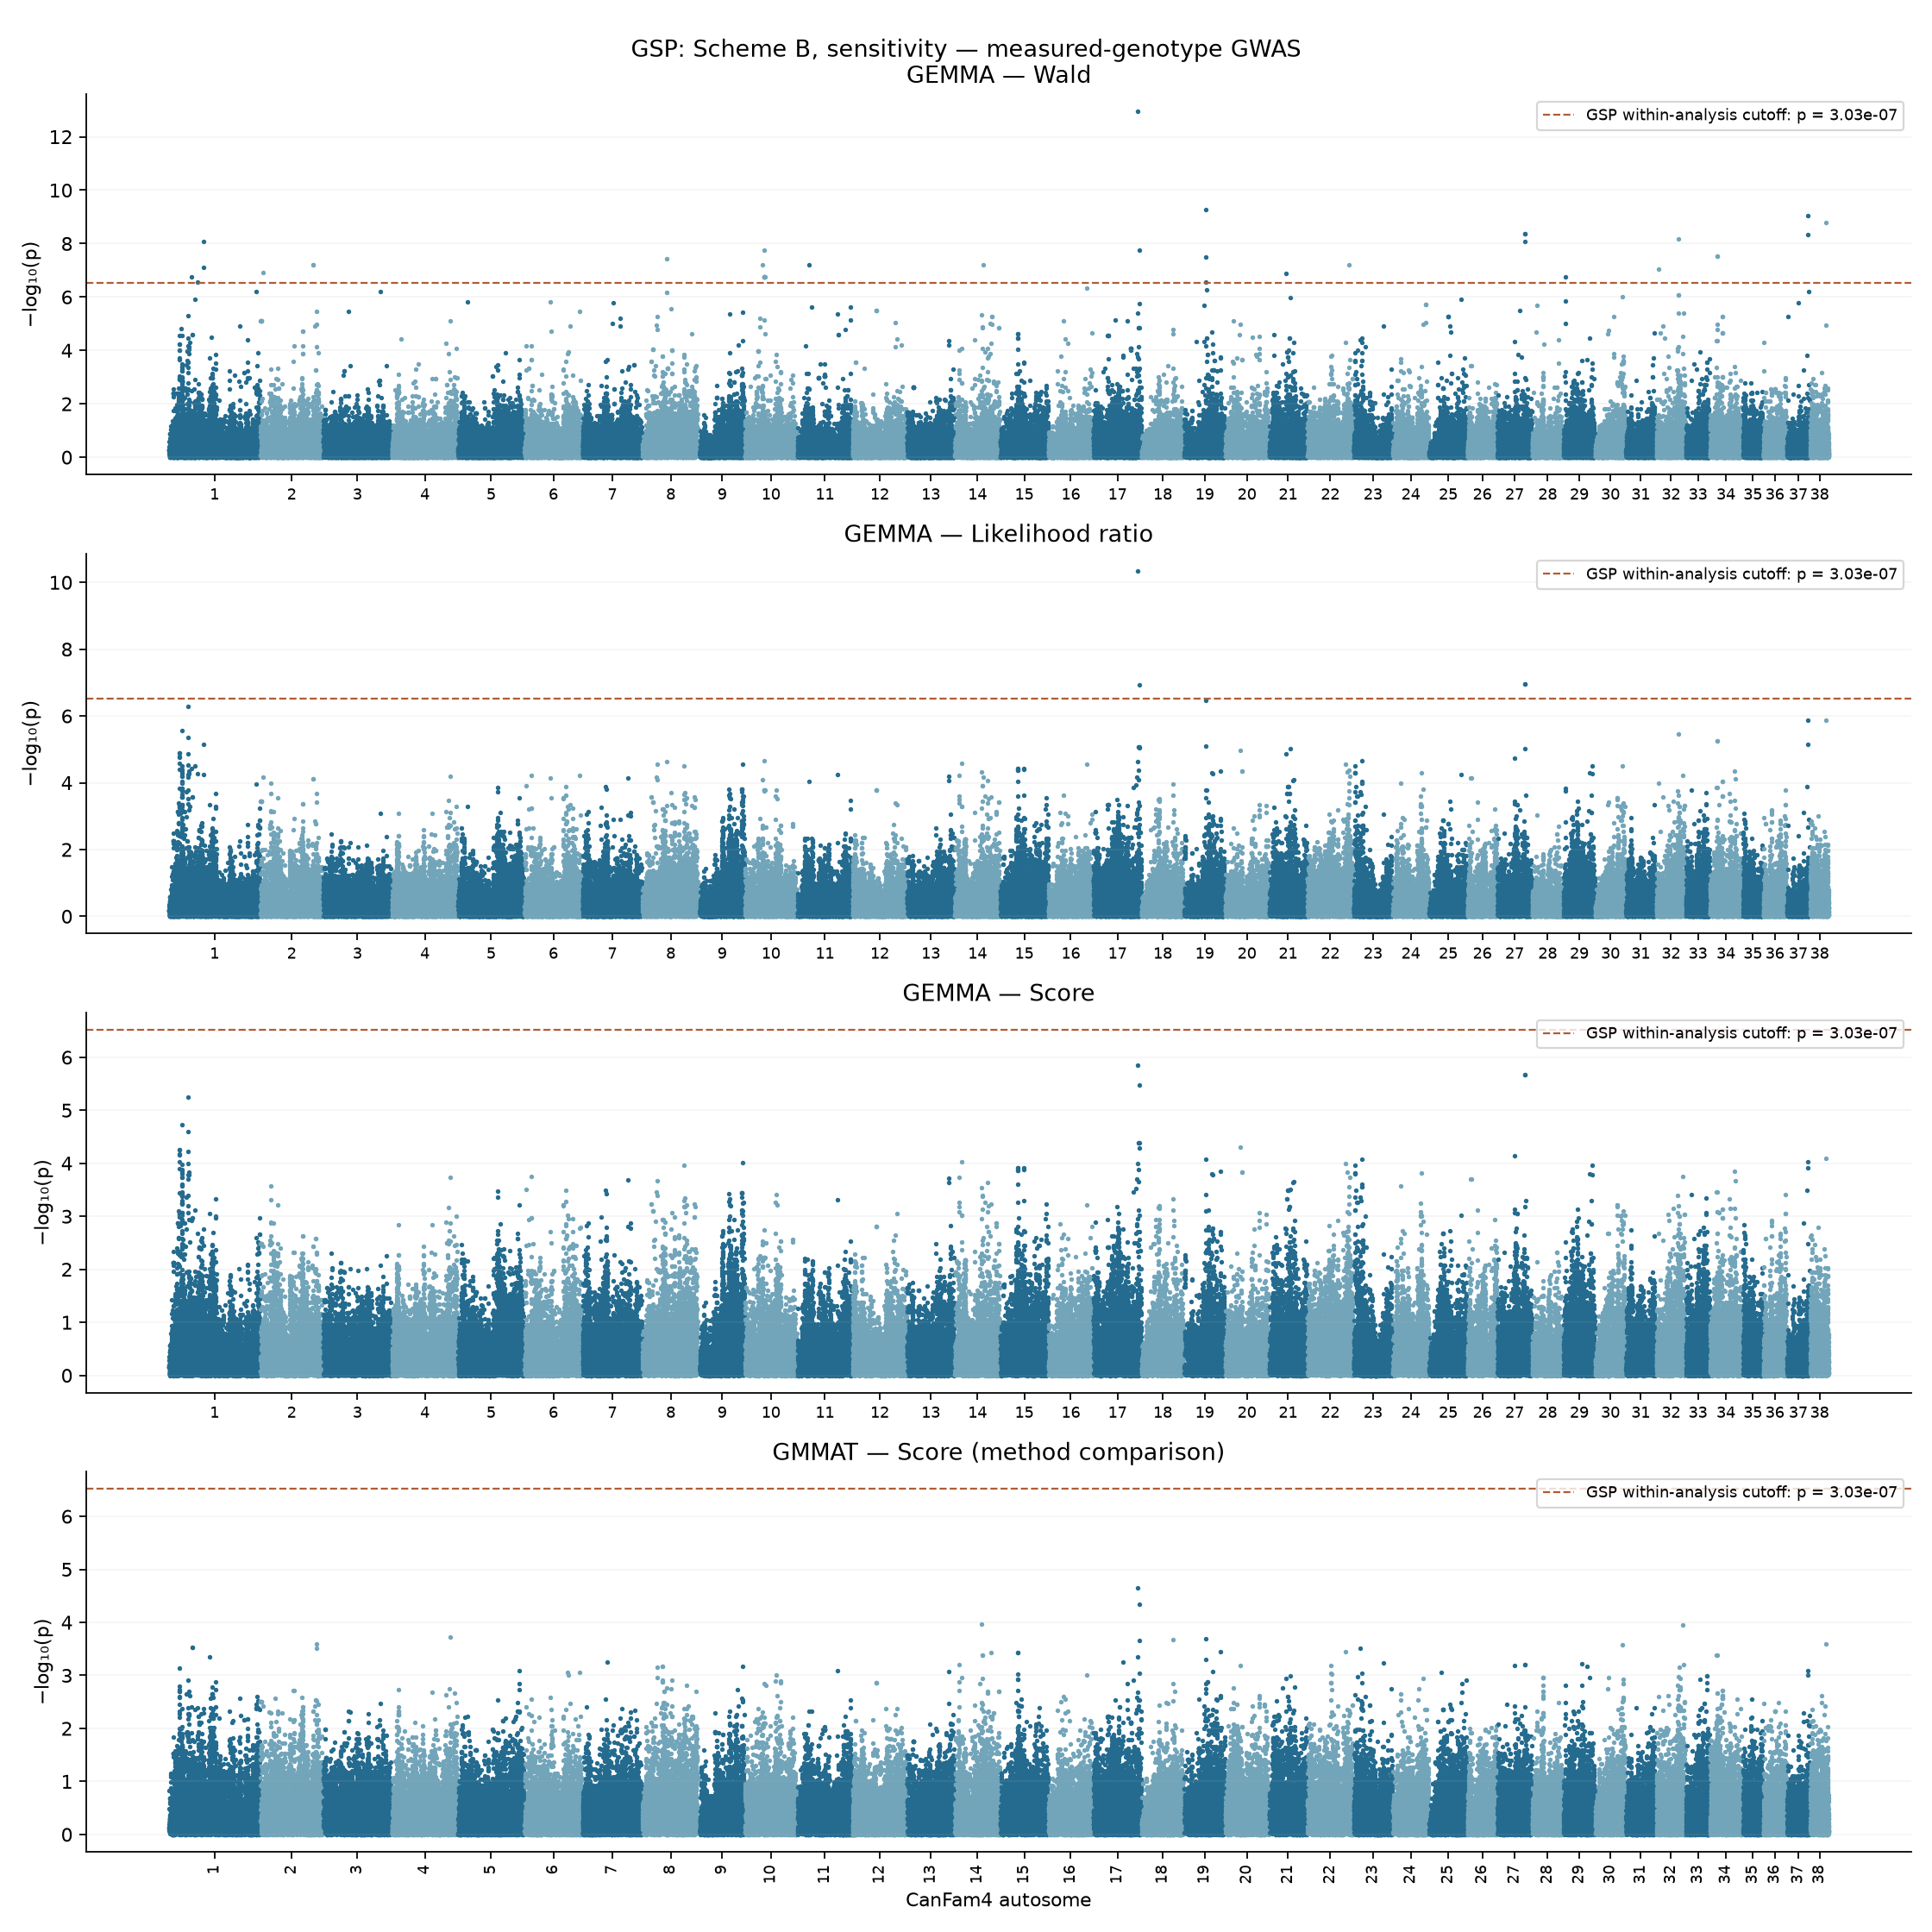

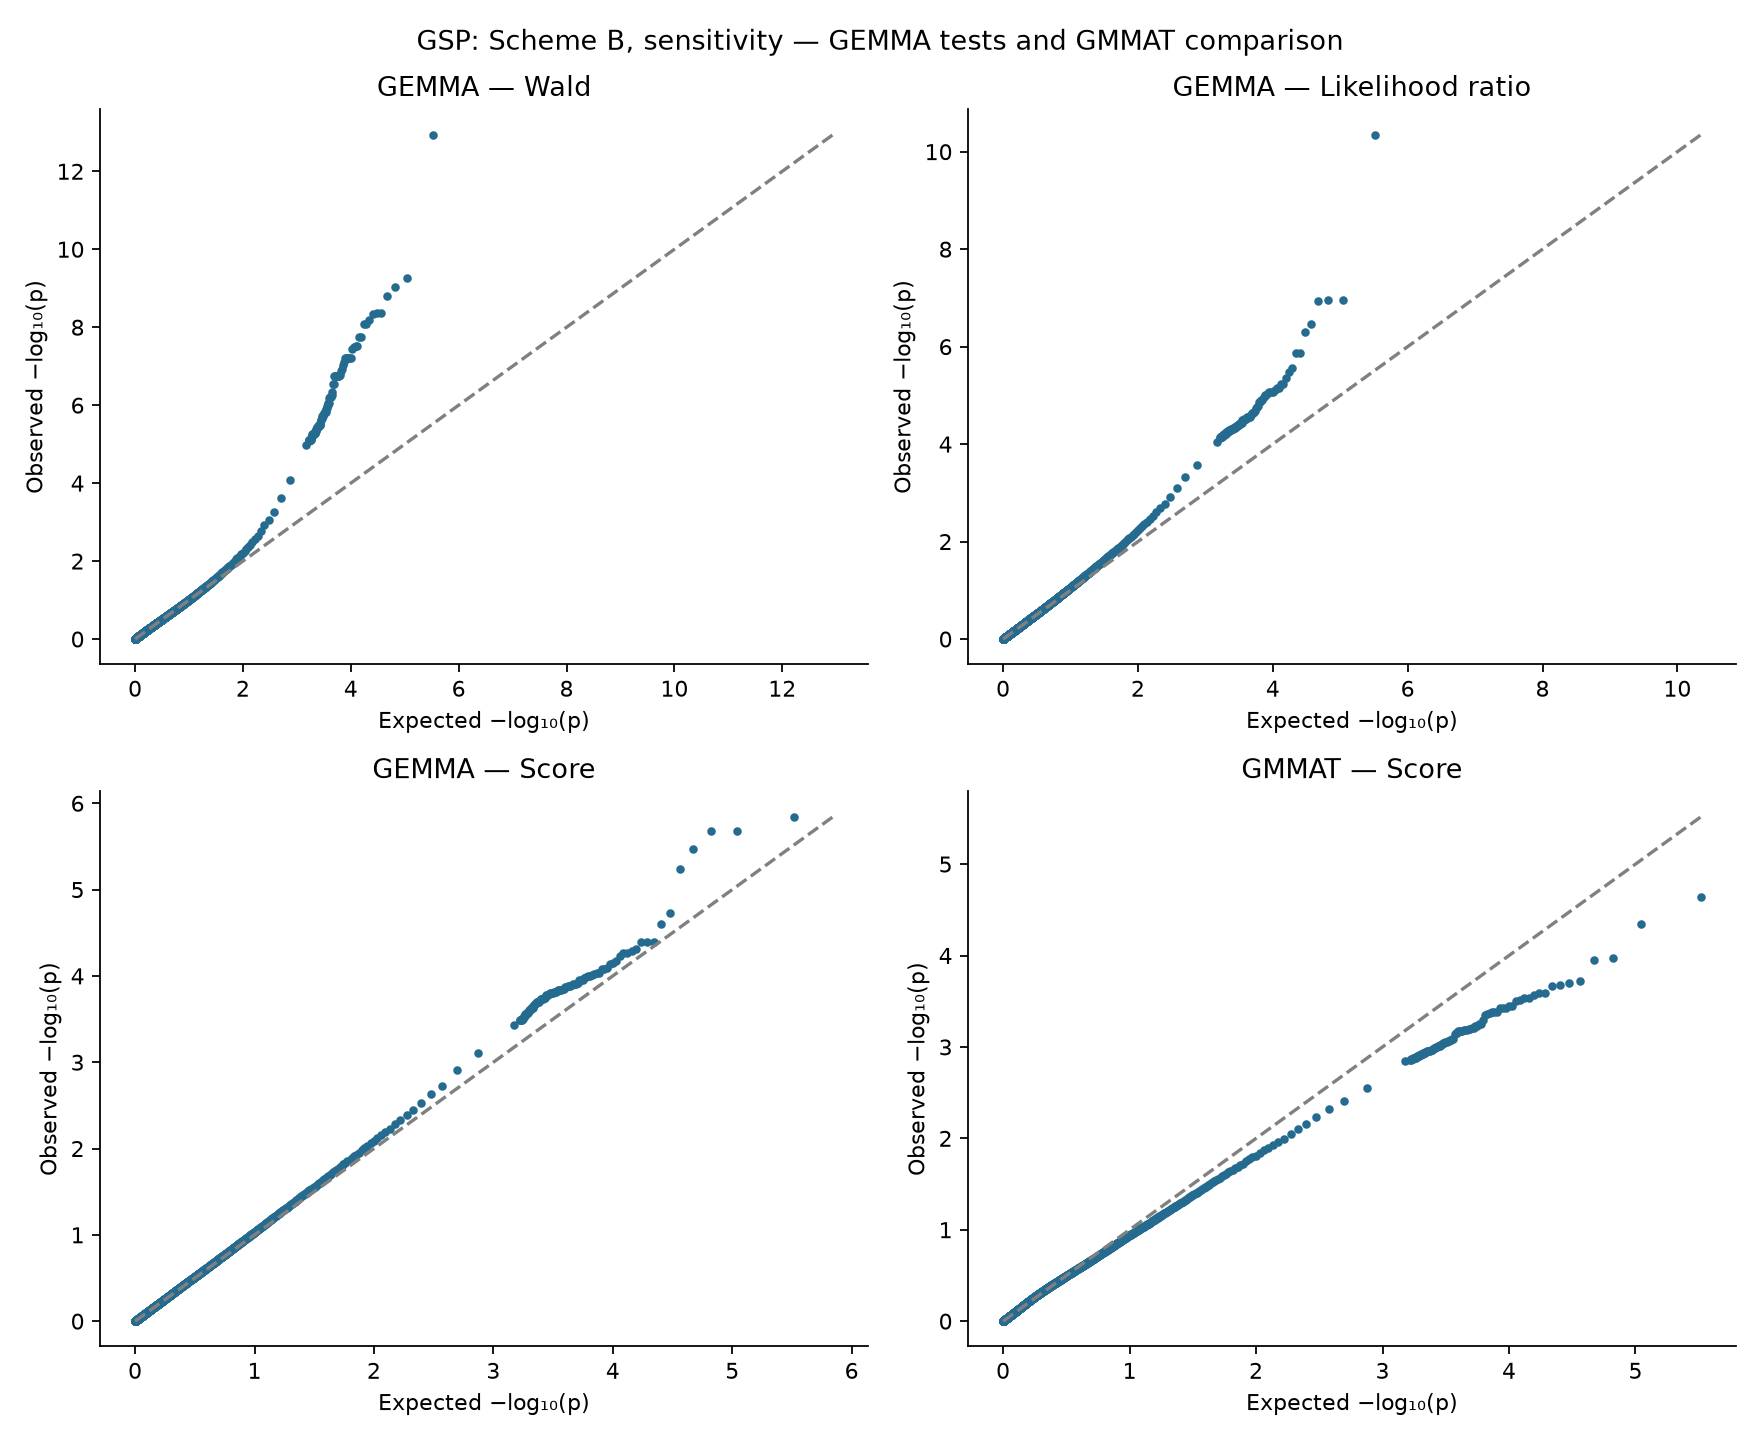

In [9]:
# Display Scheme B plots beside the primary results to assess sensitivity to the control definition.

for breed in ["LR", "GSP"]:
    display(Markdown(f"### {breed}: sensitivity comparison"))
    display(Image(filename=str(figure_folder / f"{breed}_not-behelim-vs-behelim_manhattan.png")))
    display(Image(filename=str(figure_folder / f"{breed}_not-behelim-vs-behelim_qq.png")))

- Scheme B retains 168,341 LR and 165,064 GSP markers.
- Results use the same breed-specific cutoffs, separately from Scheme A.

### (Summary) Scheme A and Scheme B Results


In [10]:
# Summarize Scheme B probabilities and candidate counts using the existing breed-specific cutoffs.
# This keeps the supporting comparison separate from the primary results.

lines = ['| Breed | Method | Test | Smallest P | Markers Below Within-Analysis Cutoff |',
         '| :---: | :---: | :---: | :---: | :---: |']
for result in summary["tests"]:
    if result["scenario"] != scans["config"]["sensitivity_cohort"]: continue
    lines.append(f"| {result['breed']} | {result['method']} | {result['test']} | "
                 f"{result['minimum_p']:.3g} | {result['below_analysis_threshold']} |")
display(Markdown("\n".join(lines)))

| Breed | Method | Test | Smallest P | Markers Below Within-Analysis Cutoff |
| :---: | :---: | :---: | :---: | :---: |
| LR | GEMMA | Wald | 1.34e-08 | 1 |
| LR | GEMMA | Likelihood ratio | 3.45e-08 | 1 |
| LR | GEMMA | Score | 2.12e-05 | 0 |
| LR | GMMAT | Score | 1.14e-05 | 0 |
| GSP | GEMMA | Wald | 1.14e-13 | 36 |
| GSP | GEMMA | Likelihood ratio | 4.45e-11 | 4 |
| GSP | GEMMA | Score | 1.43e-06 | 0 |
| GSP | GMMAT | Score | 2.27e-05 | 0 |

### (Summary) Leading Markers and Observed Counts
- The table shows each GEMMA test's leading marker with all probabilities and measured allele counts.
- Repeated markers are the same finding.
- GEMMA effects are not odds ratios.
- GMMAT score tests do not provide per-marker effects.

In [11]:
# Show each GEMMA test's leading marker with all method probabilities and observed allele counts.
# This connects apparent signals to their measured genotype support and avoids counting repeated markers as new findings.

lines = ['| Breed | Leading GEMMA Test | Marker | CanFam4 Position | Counted Allele | Case ALT / Observed Copies | Control ALT / Observed Copies | Wald P | Likelihood-Ratio P | GEMMA Score P | GMMAT Score P |',
         '| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |']
for result in summary["tests"]:
    if result["method"] != "GEMMA" or result["scenario"] != scans["config"]["primary_cohort"]: continue
    lead = result["top_variants"][0]
    lines.append(f"| {result['breed']} | {result['test']} | {lead['marker']} | chr{lead['chromosome']}:{lead['position']} | "
                 f"{lead['ALT']} | {lead['case_alt_copies']} / {2*int(lead['case_called'])} | "
                 f"{lead['control_alt_copies']} / {2*int(lead['control_called'])} | "
                 f"{lead['GEMMA_wald_p']:.3g} | {lead['GEMMA_lrt_p']:.3g} | {lead['GEMMA_p']:.3g} | {lead['GMMAT_p']:.3g} |")
display(Markdown("\n".join(lines)))
print("Converged GMMAT chromosome null models:", summary["gmmat_null_models_converged"],
      "of", summary["chromosome_null_models"])

| Breed | Leading GEMMA Test | Marker | CanFam4 Position | Counted Allele | Case ALT / Observed Copies | Control ALT / Observed Copies | Wald P | Likelihood-Ratio P | GEMMA Score P | GMMAT Score P |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| LR | Wald | BICF2P1289492 | chr8:18070392 | A | 6 / 14 | 73 / 78 | 5.77e-09 | 1.25e-08 | 1.8e-05 | 8.96e-06 |
| LR | Likelihood ratio | chr5_5738084 | chr5:5769564 | C | 9 / 14 | 77 / 78 | 1.24e-08 | 1.19e-08 | 1.78e-05 | 4.37e-05 |
| LR | Score | chr5_5738084 | chr5:5769564 | C | 9 / 14 | 77 / 78 | 1.24e-08 | 1.19e-08 | 1.78e-05 | 4.37e-05 |
| GSP | Wald | BICF2P1084604 | chr17:59758927 | T | 9 / 18 | 6 / 192 | 2.65e-12 | 6.46e-09 | 4.61e-06 | 3.96e-05 |
| GSP | Likelihood ratio | BICF2P1084604 | chr17:59758927 | T | 9 / 18 | 6 / 192 | 2.65e-12 | 6.46e-09 | 4.61e-06 | 3.96e-05 |
| GSP | Score | BICF2P1084604 | chr17:59758927 | T | 9 / 18 | 6 / 192 | 2.65e-12 | 6.46e-09 | 4.61e-06 | 3.96e-05 |

Converged GMMAT chromosome null models: 152 of 152


### Interpretation Limits
- Signals need further small-sample assessment and reliable effect estimation.
- Nonsignificance does not establish absence of association.
- Imputed variants remain outside these scans.
- [GWAS methods](../docs/methods/07%20Breed-specific%20measured%20GWAS.md) document implementation and reporting.